# Planar classification: backprop vs discriminative predictive coding

A complete, function-by-function NumPy walkthrough alongside `planar_+1n.ipynb`.

Both networks use **2 inputs → 6 hidden units → 4 hidden units → 1 output**, **tanh → tanh → sigmoid**, and binary cross-entropy (BCE) at the output. Each column is one example. Learning calculations use NumPy; plots use Matplotlib. The supplied `planar_utils.py` also imports scikit-learn.

Read and run the cells in order. First we reuse the familiar forward pass, then introduce adjustable hidden activities, inference, and local weight updates. The final cells check the derivatives and compare training from identical initial weights.

## 1 — Load and inspect the same data

Run from the repository root so Python can import `planar_utils.py`.

- `X.shape == (2, 400)`: two input coordinates per point.
- `Y.shape == (1, 400)`: one binary label per point.

`load_planar_dataset()` sets seed `1`, reproducing the flower dataset in your backprop notebook. Data loading is the same for both learning algorithms.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from planar_utils import load_planar_dataset, plot_decision_boundary

X, Y = load_planar_dataset()

assert X.shape == (2, 400)
assert Y.shape == (1, X.shape[1])
assert np.isfinite(X).all()
assert np.array_equal(np.unique(Y), np.array([0, 1]))

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("First input column:", X[:, 0])
print("Its label:", Y[0, 0])
print("Its label:", X[0, 0])



X shape: (2, 400)
Y shape: (1, 400)
First input column: [1.20444229 3.57611415]
Its label: 0
Its label: 1.204442292254319


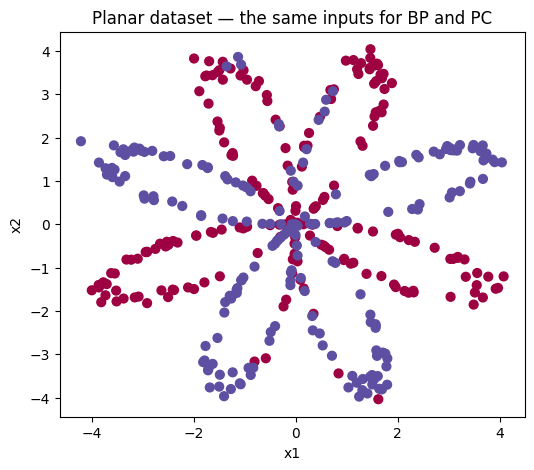

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[0, :], X[1, :], c=Y.ravel(), cmap=plt.cm.Spectral, s=40)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Planar dataset — the same inputs for BP and PC")
plt.show()


## 2 — Define the architecture (`layers`)

This function does the same job as `layers` in your notebook. The extra arrays needed for PC will be **activities**, not extra layers or extra weights.

| Layer | Units | Weight shape | Bias shape | Batch activity shape |
|---|---:|---|---|---|
| Input | 2 | — | — | `(2, m)` |
| Hidden 1 | 6 | `(6, 2)` | `(6, 1)` | `(6, m)` |
| Hidden 2 | 4 | `(4, 6)` | `(4, 1)` | `(4, m)` |
| Output | 1 | `(1, 4)` | `(1, 1)` | `(1, m)` |

In [3]:
def layers(X, Y):
    x_n = X.shape[0]
    h_1 = 6
    h_2 = 4
    y_n = Y.shape[0]
    return x_n, h_1, h_2, y_n

print("Layer sizes:", layers(X, Y))

Layer sizes: (2, 6, 4, 1)


## 3 — Initialize weights and biases (`initialize_parameters`)

We keep your initialization: small positive uniform weights for `W1` and `W2`, uniform weights for `W3`, and zero biases. A local random generator with seed `3` reproduces your draws without changing NumPy's global random state.

Later, PC and BP will receive **copies of exactly the same parameters**. This isolates the training-rule comparison. Your original notebook uses weight learning rate `1.2`; our controlled comparison starts both algorithms at `0.1`.

In [4]:
def initialize_parameters(x_n, h_1, h_2, y_n, seed=3):
    rng = np.random.RandomState(seed)
    return {
        "W1": rng.rand(h_1, x_n) * 0.01,
        "b1": np.zeros((h_1, 1)),
        "W2": rng.rand(h_2, h_1) * 0.01,
        "b2": np.zeros((h_2, 1)),
        "W3": rng.rand(y_n, h_2),
        "b3": np.zeros((y_n, 1)),
    }

initial_parameters = initialize_parameters(*layers(X, Y))
for name, value in initial_parameters.items():
    print(name, value.shape)

W1 (6, 2)
b1 (6, 1)
W2 (4, 6)
b2 (4, 1)
W3 (1, 4)
b3 (1, 1)


## 4 — The familiar forward pass (`forward_propagation`)

These are your existing forward equations. As in your original code, `np.dot` performs matrix multiplication. We use a stable sigmoid so very large logits do not overflow. Hidden activation derivatives are still `1 - tanh(z)**2`.

A **prediction** is what a layer computes from the previous layer. A PC **activity** is a separate variable that inference may adjust. During this forward pass they initially agree. At test time, the forward pass alone supplies class probabilities; no labels are needed.

In [5]:
def sigmoid(Z):
    # exp(-abs(Z)) is safe even for large positive or negative Z.
    exp_neg_abs = np.exp(-np.abs(Z))
    return np.where(Z >= 0, 1 / (1 + exp_neg_abs),
                    exp_neg_abs / (1 + exp_neg_abs))


def forward_propagation(parameters, X):
    Z1 = np.dot(parameters["W1"], X) + parameters["b1"]
    A1 = np.tanh(Z1)
    Z2 = np.dot(parameters["W2"], A1) + parameters["b2"]
    A2 = np.tanh(Z2)
    Z3 = np.dot(parameters["W3"], A2) + parameters["b3"]
    A3 = sigmoid(Z3)
    cache = {"Z1": Z1, "A1": A1, "Z2": Z2,
             "A2": A2, "Z3": Z3, "A3": A3}
    assert A3.shape == (1, X.shape[1])
    return A3, cache


A3, cache = forward_propagation(initial_parameters, X)
print("Forward activation shapes:", cache["A1"].shape,
      cache["A2"].shape, A3.shape)

Forward activation shapes: (6, 400) (4, 400) (1, 400)


## 5 — Classification cost (`compute_cost`)

Same BCE as your notebook, computed directly from logits:

$$
L = \frac{1}{m}\sum_j [\log(1+e^{Z_{3,j}})-Y_j Z_{3,j}].
$$

`np.logaddexp(0, Z3)` evaluates the first term safely. This avoids taking `log(0)` when sigmoid saturates. This **forward classification loss** will be the common metric for BP and PC. It is different from the PC energy during inference.

In [6]:
def compute_cost(Y, cache):
    Z3 = cache["Z3"]
    return float(np.sum(np.logaddexp(0, Z3) - Y * Z3) / Y.shape[1])

print("Initial forward BCE:", compute_cost(Y, cache))

Initial forward BCE: 0.6931973978771083


## 6 — Initialize PC hidden activities (`initialize_activities`)

This is the first new function. Make independent copies of the forward hidden activations:

$$
H_1 \leftarrow A_1, \qquad H_2 \leftarrow A_2.
$$

`H1` and `H2` have shapes `(6, m)` and `(4, m)`. Inference will change them while the weights stay fixed. These are post-activation activity variables, initialized using tanh. They are not constrained to remain in `[-1, 1]` during inference; applying tanh again or clipping them would change the algorithm.

`X` and `Y` stay fixed. We do not maintain an adjustable output activity: the fixed binary label appears in a Bernoulli/BCE output term.

In [7]:
def initialize_activities(cache):
    return {"H1": cache["A1"].copy(), "H2": cache["A2"].copy()}

activities = initialize_activities(cache)
assert not np.shares_memory(activities["H1"], cache["A1"])
print("Activity shapes:", activities["H1"].shape, activities["H2"].shape)

Activity shapes: (6, 400) (4, 400)


## 7 — Compute local predictions and errors (`compute_prediction_errors`)

Choose the sign convention **activity minus prediction**:

$$
\begin{aligned}
\mu_1 &= \tanh(W_1X+b_1), & e_1 &= H_1-\mu_1,\\
\mu_2 &= \tanh(W_2H_1+b_2), & e_2 &= H_2-\mu_2,\\
p &= \sigma(W_3H_2+b_3), & \delta_3 &= p-Y.
\end{aligned}
$$

`mu2` depends on the **current inferred `H1`**, not the original forward `A1`. Likewise the output depends on the current `H2`. Recompute these predictions each inference step.

`delta3` is the derivative of BCE with respect to the output logit. Just as in your backprop code, sigmoid plus BCE gives `p - Y`; do **not** multiply it by another sigmoid derivative. The hidden errors are Gaussian residuals; the output uses a Bernoulli likelihood instead.

In [8]:
def compute_prediction_errors(parameters, X, Y, activities):
    H1, H2 = activities["H1"], activities["H2"]
    mu1 = np.tanh(np.dot(parameters["W1"], X) + parameters["b1"])
    mu2 = np.tanh(np.dot(parameters["W2"], H1) + parameters["b2"])
    Z3 = np.dot(parameters["W3"], H2) + parameters["b3"]
    p = sigmoid(Z3)
    return {"mu1": mu1, "mu2": mu2, "Z3": Z3, "p": p,
            "e1": H1 - mu1, "e2": H2 - mu2, "delta3": p - Y}


errors = compute_prediction_errors(initial_parameters, X, Y, activities)
assert np.allclose(errors["e1"], 0)
assert np.allclose(errors["e2"], 0)
print("Initial hidden error norms:", np.linalg.norm(errors["e1"]),
      np.linalg.norm(errors["e2"]))
print("Initial output error norm:", np.linalg.norm(errors["delta3"]))

Initial hidden error norms: 0.0 0.0
Initial output error norm: 10.000502160526164


## 8 — Define the PC energy (`compute_energy`)

With unit hidden precisions and output coefficient 1:

$$
E = \frac{1}{m}\left[\frac12\|e_1\|_F^2
+\frac12\|e_2\|_F^2
+\sum_j \operatorname{BCE}(Y_j,p_j)\right].
$$

Inference reduces this energy by adjusting the hidden activities. Weight learning then reduces it with respect to the parameters while holding the inferred activities fixed. At forward initialization the two hidden error terms are zero, so energy equals the forward BCE. After inference, energy and forward BCE are different quantities.

In [9]:
def compute_energy(Y, errors):
    hidden = 0.5 * (np.sum(errors["e1"]**2) + np.sum(errors["e2"]**2))
    output = np.sum(np.logaddexp(0, errors["Z3"]) - Y * errors["Z3"])
    return float((hidden + output) / Y.shape[1])

assert np.isclose(compute_energy(Y, errors), compute_cost(Y, cache))
print("Initial PC energy:", compute_energy(Y, errors))

Initial PC energy: 0.6931973978771083


## 9 — Derive activity gradients (`activity_gradients`)

For one example, write its unaveraged energy as $\mathcal E_j$. Differentiating with respect to its activities gives:

$$
\begin{aligned}
g_{H_1} &= e_1-W_2^T\left[e_2\odot(1-\mu_2^2)\right],\\
g_{H_2} &= e_2+W_3^T\delta_3.
\end{aligned}
$$

Each hidden activity receives a restoring term from its own prediction error and a feedback term from the layer above. The minus sign in `gH1` comes from `e2 = H2 - mu2`. The plus sign in `gH2` comes from the BCE derivative `p - Y`.

We return **per-example** activity derivatives without `/m`, so the inference rate does not change when the batch size changes. The derivative of the reported mean energy is these arrays divided by `m`. This normalization matters in the finite-difference checks below.

In [10]:
def activity_gradients(parameters, errors):
    gH1 = errors["e1"] - np.dot(parameters["W2"].T, errors["e2"] * (1 - errors["mu2"]**2))
    gH2 = errors["e2"] + np.dot(parameters["W3"].T, errors["delta3"])
    return {"H1": gH1, "H2": gH2}

## 10 — Infer hidden activities (`infer_activities`)

This **inner loop** replaces the single backward gradient sweep as the source of PC's teaching signals:

$$
H_1 \leftarrow H_1-\eta_x g_{H_1},\qquad
H_2 \leftarrow H_2-\eta_x g_{H_2}.
$$

Compute both gradients from the same old state, then update both activities simultaneously. Freeze weights for all inference steps. Finally recompute the errors at the updated state so the subsequent weight update uses consistent values.

At initialization, `e1 = e2 = 0`. The label first moves `H2`; its mismatch then influences `H1` on later steps. A fixed budget of 20 steps approximates inference rather than guaranteeing an exact equilibrium. If a step is too large, energy may increase; the trace lets us check this.

Energy before inference: 0.6931973978771083
Energy after 20 steps: 0.6001019323542127
Hidden activity changes: 0.11483049396100038 7.241933326309491


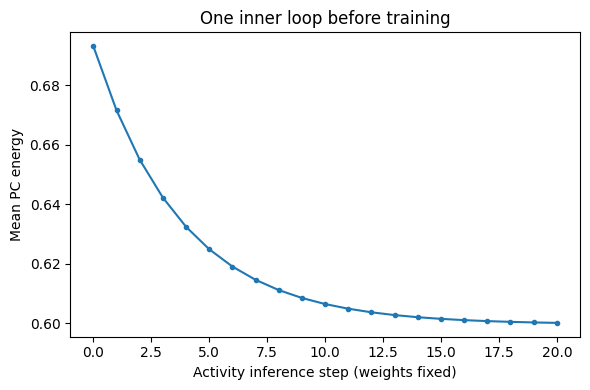

In [11]:
def infer_activities(parameters, X, Y, cache, num_steps=20,
                     activity_rate=0.1, record_energy=False):
    if num_steps < 0 or int(num_steps) != num_steps:
        raise ValueError("num_steps must be a nonnegative integer")
    if activity_rate <= 0:
        raise ValueError("activity_rate must be positive")
    activities = initialize_activities(cache)
    errors = compute_prediction_errors(parameters, X, Y, activities)
    energy_trace = [compute_energy(Y, errors)] if record_energy else []

    for _ in range(num_steps):
        grads = activity_gradients(parameters, errors)
        activities = {
            "H1": activities["H1"] - activity_rate * grads["H1"],
            "H2": activities["H2"] - activity_rate * grads["H2"],
        }
        errors = compute_prediction_errors(parameters, X, Y, activities)
        if record_energy:
            energy_trace.append(compute_energy(Y, errors))

    return activities, errors, np.asarray(energy_trace)


inferred, inferred_errors, first_trace = infer_activities(
    initial_parameters, X, Y, cache, record_energy=True)
print("Energy before inference:", first_trace[0])
print("Energy after 20 steps:", first_trace[-1])
print("Hidden activity changes:",
      np.linalg.norm(inferred["H1"] - cache["A1"]),
      np.linalg.norm(inferred["H2"] - cache["A2"]))
plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(first_trace)), first_trace, marker=".")
plt.xlabel("Activity inference step (weights fixed)")
plt.ylabel("Mean PC energy")
plt.title("One inner loop before training")
plt.tight_layout()
plt.show()

## 11 — Compute local parameter gradients (`local_parameter_gradients`)

Hold `H1` and `H2` fixed. For each hidden layer, differentiate its own squared prediction error. Define the local preactivation gradients:

$$
s_1=-e_1\odot(1-\mu_1^2),\qquad
s_2=-e_2\odot(1-\mu_2^2),\qquad
s_3=p-Y.
$$

Then:

$$
\begin{array}{lll}
\nabla_{W_1}E=s_1X^T/m,&
\nabla_{W_2}E=s_2H_1^T/m,&
\nabla_{W_3}E=s_3H_2^T/m.
\end{array}
$$

Bias gradients are the column means of the corresponding `s`. The hidden minus signs follow from our **activity minus prediction** convention. We return gradients and later **subtract** them, just as your `update_parameters` function does.

Each weight gradient uses the layer's local prediction error and input activity. Feedback with transposed weights still occurs during inference. We are not claiming that feedback connections or activation derivatives disappear.

In [12]:
def local_parameter_gradients(X, activities, errors):
    m = X.shape[1]
    s1 = -errors["e1"] * (1 - errors["mu1"]**2)
    s2 = -errors["e2"] * (1 - errors["mu2"]**2)
    s3 = errors["delta3"]
    return {
        "dW1": (np.dot(s1, X.T)) / m,
        "db1": np.mean(s1, axis=1, keepdims=True),
        "dW2": (np.dot(s2, activities["H1"].T)) / m,
        "db2": np.mean(s2, axis=1, keepdims=True),
        "dW3": (np.dot(s3, activities["H2"].T)) / m,
        "db3": np.mean(s3, axis=1, keepdims=True),
    }

## 12 — Update the weights (`update_parameters`)

Same operation as backprop: `parameter - weight_rate * gradient`. PC changes **how the gradients are obtained**, not this subtraction. There are two separate rates: `activity_rate` for the inner inference loop and `weight_rate` for the outer learning loop.

Return a new dictionary so neither training run changes its shared starting parameters.

In [13]:
def update_parameters(parameters, grads, weight_rate=0.1):
    if weight_rate <= 0:
        raise ValueError("weight_rate must be positive")
    return {name: value - weight_rate * grads["d" + name]
            for name, value in parameters.items()}

## 13 — Check the equations before training

These small numerical checks differentiate the energy directly by central finite differences. They check every activity and parameter entry on a tiny batch with perturbed activities, where hidden residuals are nonzero.

For parameter checks, activities stay fixed. Differentiating *through* inference would test a different algorithm. We also check that inference leaves weights unchanged, a small inference step reduces energy, and extreme logits have finite BCE.

In [14]:
def check_pc_gradients():
    rng = np.random.RandomState(12)
    tiny_X = X[:, :3]
    tiny_Y = Y[:, :3].astype(float)
    tiny_Y[0, 1] = 1.0  # Exercise both output classes.
    params = initialize_parameters(2, 3, 2, 1, seed=8)
    # Non-tiny weights exercise feedback and tanh derivatives.
    for name in ("W1", "W2", "W3"):
        params[name] = rng.normal(scale=0.2, size=params[name].shape)
    _, tiny_cache = forward_propagation(params, tiny_X)
    state = initialize_activities(tiny_cache)
    for value in state.values():
        value += rng.normal(scale=0.1, size=value.shape)

    def energy():
        return compute_energy(tiny_Y, compute_prediction_errors(
            params, tiny_X, tiny_Y, state))

    residuals = compute_prediction_errors(params, tiny_X, tiny_Y, state)
    activity_grads = activity_gradients(params, residuals)
    weight_grads = local_parameter_gradients(tiny_X, state, residuals)
    eps = 1e-6
    max_error = 0.0
    for arrays, grads, prefix, divisor in (
        (state, activity_grads, "", tiny_X.shape[1]),
        (params, weight_grads, "d", 1),
    ):
        for name, array in arrays.items():
            numerical = np.empty_like(array)
            for index in np.ndindex(array.shape):
                old = array[index]
                array[index] = old + eps
                plus = energy()
                array[index] = old - eps
                minus = energy()
                array[index] = old
                numerical[index] = (plus - minus) / (2 * eps)
            analytical = grads[prefix + name] / divisor
            np.testing.assert_allclose(analytical, numerical, atol=1e-7, rtol=1e-5)
            max_error = max(max_error, float(np.max(np.abs(analytical - numerical))))

    before = {name: value.copy() for name, value in params.items()}
    untouched_cache = {name: value.copy() for name, value in tiny_cache.items()}
    state0, errors0, _ = infer_activities(params, tiny_X, tiny_Y, tiny_cache, num_steps=0)
    assert np.allclose(errors0["e1"], 0) and np.allclose(errors0["e2"], 0)
    _, _, trace = infer_activities(params, tiny_X, tiny_Y, tiny_cache,
                                  num_steps=30, activity_rate=0.05, record_energy=True)
    assert trace[-1] < trace[0]
    assert np.all(np.diff(trace) <= 1e-12)
    for name in params:
        np.testing.assert_array_equal(params[name], before[name])
    for name in tiny_cache:
        np.testing.assert_array_equal(tiny_cache[name], untouched_cache[name])
    extreme = np.array([[-1000., 1000.]])
    np.testing.assert_allclose(sigmoid(extreme), [[0., 1.]])
    assert np.isfinite(compute_cost(np.array([[1., 0.]]), {"Z3": extreme}))
    print(f"PC finite-difference checks passed; max absolute error = {max_error:.2e}")
    print("Inference energy decrease, fixed weights/cache, zero-step and stability checks passed.")


check_pc_gradients()

PC finite-difference checks passed; max absolute error = 9.22e-11
Inference energy decrease, fixed weights/cache, zero-step and stability checks passed.


## 14 — Assemble PC training (`pc_model`)

One outer iteration is:

1. Forward pass with current weights.
2. Initialize hidden activities from the forward pass.
3. Infer activities with fixed weights.
4. Compute local weight gradients using the final inferred state.
5. Update weights once; discard the activities before the next iteration.

We record **forward BCE and forward accuracy** every 100 updates, including iteration 0 and the final iteration. `inference_start_energy` and `inference_end_energy` refer to the inner loop immediately before the associated weight update. Their curve is diagnostic; it is not the forward classification loss.

The defaults implement ordinary discriminative PC with finite inference. This version does not use fixed predictions or an exact-backprop construction.

In [15]:
def predict(parameters, X):
    probabilities, _ = forward_propagation(parameters, X)
    return probabilities > 0.5


def pc_model(X, Y, h1=6, h2=4, num_iterations=10000,
             weight_rate=0.1, activity_rate=0.1, inference_steps=20,
             print_cost=True, initial_parameters=None, log_every=100):
    if num_iterations < 0 or int(num_iterations) != num_iterations or log_every < 1:
        raise ValueError("Use nonnegative integer iterations and positive log_every")
    source = (initialize_parameters(X.shape[0], h1, h2, Y.shape[0])
              if initial_parameters is None else initial_parameters)
    parameters = {name: value.copy() for name, value in source.items()}
    history = {"iteration": [], "cost": [], "accuracy": [],
               "inference_start_energy": [], "inference_end_energy": []}
    start_energy = end_energy = np.nan  # No preceding inference at iteration 0.

    for iteration in range(num_iterations + 1):
        probabilities, cache = forward_propagation(parameters, X)
        if iteration % log_every == 0 or iteration == num_iterations:
            cost = compute_cost(Y, cache)
            accuracy = float(np.mean((probabilities > 0.5) == Y))
            if not np.isfinite(cost) or not all(
                    np.isfinite(value).all() for value in parameters.values()):
                raise FloatingPointError("Non-finite PC training state; reduce learning rates")
            for name, value in (("iteration", iteration), ("cost", cost),
                                ("accuracy", accuracy),
                                ("inference_start_energy", start_energy),
                                ("inference_end_energy", end_energy)):
                history[name].append(value)
            if print_cost and (iteration % 1000 == 0 or iteration == num_iterations):
                print(f"PC {iteration:5d}: forward BCE={cost:.6f}, accuracy={accuracy:.1%}")
        if iteration == num_iterations:
            break

        activities, errors, _ = infer_activities(
            parameters, X, Y, cache, num_steps=inference_steps,
            activity_rate=activity_rate)
        start_energy = compute_cost(Y, cache)  # Initial hidden residuals are zero.
        end_energy = compute_energy(Y, errors)
        grads = local_parameter_gradients(X, activities, errors)
        parameters = update_parameters(parameters, grads, weight_rate)

    return parameters, {name: np.asarray(values) for name, values in history.items()}

## 15 — A matching BP reference

These are the same chain-rule equations as your `backwared_propagation`, with consistent spelling. `bp_model` uses the same forward pass, cost, update function, initialization, iteration count, and weight rate as PC.

BP calculates `dZ2` and `dZ1` in a backward sweep using feedforward activations. PC instead relaxes hidden activities, then obtains local parameter gradients. PC takes more computation per weight update; equal iteration counts are not equal runtime.

In [16]:
def backward_propagation(cache, parameters, X, Y):
    m = X.shape[1]
    dZ3 = cache["A3"] - Y
    dZ2 = (np.dot(parameters["W3"].T, dZ3)) * (1 - cache["A2"]**2)
    dZ1 = (np.dot(parameters["W2"].T, dZ2)) * (1 - cache["A1"]**2)
    return {
        "dW1": (np.dot(dZ1, X.T)) / m,
        "db1": np.mean(dZ1, axis=1, keepdims=True),
        "dW2": (np.dot(dZ2, cache["A1"].T)) / m,
        "db2": np.mean(dZ2, axis=1, keepdims=True),
        "dW3": (np.dot(dZ3, cache["A2"].T)) / m,
        "db3": np.mean(dZ3, axis=1, keepdims=True),
    }


def bp_model(X, Y, initial_parameters, num_iterations=10000,
             weight_rate=0.1, print_cost=True, log_every=100):
    parameters = {name: value.copy() for name, value in initial_parameters.items()}
    history = {"iteration": [], "cost": [], "accuracy": []}
    for iteration in range(num_iterations + 1):
        probabilities, cache = forward_propagation(parameters, X)
        if iteration % log_every == 0 or iteration == num_iterations:
            cost = compute_cost(Y, cache)
            accuracy = float(np.mean((probabilities > 0.5) == Y))
            history["iteration"].append(iteration)
            history["cost"].append(cost)
            history["accuracy"].append(accuracy)
            if print_cost and (iteration % 1000 == 0 or iteration == num_iterations):
                print(f"BP {iteration:5d}: forward BCE={cost:.6f}, accuracy={accuracy:.1%}")
        if iteration == num_iterations:
            break
        grads = backward_propagation(cache, parameters, X, Y)
        parameters = update_parameters(parameters, grads, weight_rate)
    return parameters, {name: np.asarray(values) for name, values in history.items()}

## 16 — Train both networks from identical weights

Use 10,000 weight updates for each method, learning rate `0.1`, and 20 activity inference steps at rate `0.1` for PC. We time both runs so the cost of inference is visible. This is a training-data demonstration, not a held-out generalization benchmark.

The assertions require finite values and improvement over initialization, not equal gradients, equal accuracy, or a claim that one method is universally better. If you change hyperparameters, inspect both the forward loss and inference stability.

In [17]:
from time import perf_counter

NUM_ITERATIONS = 10000
WEIGHT_RATE = 0.1
ACTIVITY_RATE = 0.1
INFERENCE_STEPS = 20

shared_initial = initialize_parameters(*layers(X, Y), seed=3)
shared_snapshot = {name: value.copy() for name, value in shared_initial.items()}

start = perf_counter()
pc_parameters, pc_history = pc_model(
    X, Y, initial_parameters=shared_initial, num_iterations=NUM_ITERATIONS,
    weight_rate=WEIGHT_RATE, activity_rate=ACTIVITY_RATE,
    inference_steps=INFERENCE_STEPS)
pc_seconds = perf_counter() - start

start = perf_counter()
bp_parameters, bp_history = bp_model(
    X, Y, shared_initial, num_iterations=NUM_ITERATIONS, weight_rate=WEIGHT_RATE)
bp_seconds = perf_counter() - start

for name, value in shared_initial.items():
    np.testing.assert_array_equal(value, shared_snapshot[name])
for history in (pc_history, bp_history):
    assert np.isfinite(history["cost"]).all()
    assert history["cost"][-1] < history["cost"][0]
    assert history["accuracy"][-1] > history["accuracy"][0]
    assert history["iteration"][-1] == NUM_ITERATIONS
for params in (pc_parameters, bp_parameters):
    assert all(np.isfinite(value).all() for value in params.values())

print("\nMethod    Final BCE   Training accuracy   Elapsed (this machine)")
for label, history, seconds in (("PC", pc_history, pc_seconds),
                                ("BP", bp_history, bp_seconds)):
    print(f"{label:6s}    {history['cost'][-1]:.5f}       "
          f"{history['accuracy'][-1]:.1%}             {seconds:.2f}s")
print("Checks passed: both methods improved; shared initialization was unchanged.")

PC     0: forward BCE=0.693197, accuracy=40.0%
PC  1000: forward BCE=0.695471, accuracy=47.0%
PC  2000: forward BCE=0.702361, accuracy=47.0%
PC  3000: forward BCE=0.702125, accuracy=46.5%
PC  4000: forward BCE=0.674440, accuracy=49.5%
PC  5000: forward BCE=0.581523, accuracy=75.5%
PC  6000: forward BCE=0.474524, accuracy=81.0%
PC  7000: forward BCE=0.450230, accuracy=83.2%
PC  8000: forward BCE=0.439557, accuracy=84.0%
PC  9000: forward BCE=0.440861, accuracy=84.2%
PC 10000: forward BCE=0.452451, accuracy=84.5%
BP     0: forward BCE=0.693197, accuracy=40.0%
BP  1000: forward BCE=0.367764, accuracy=87.0%
BP  2000: forward BCE=0.305555, accuracy=88.2%
BP  3000: forward BCE=0.288842, accuracy=88.2%
BP  4000: forward BCE=0.279621, accuracy=88.8%
BP  5000: forward BCE=0.271931, accuracy=89.5%
BP  6000: forward BCE=0.264798, accuracy=89.5%
BP  7000: forward BCE=0.259862, accuracy=89.5%
BP  8000: forward BCE=0.256306, accuracy=89.5%
BP  9000: forward BCE=0.253575, accuracy=89.5%
BP 10000: for

## 17 — Compare forward classification loss and accuracy

Both curves use predictions computed by an ordinary forward pass. Comparing PC's relaxed training energy against BP's forward BCE would compare different quantities.

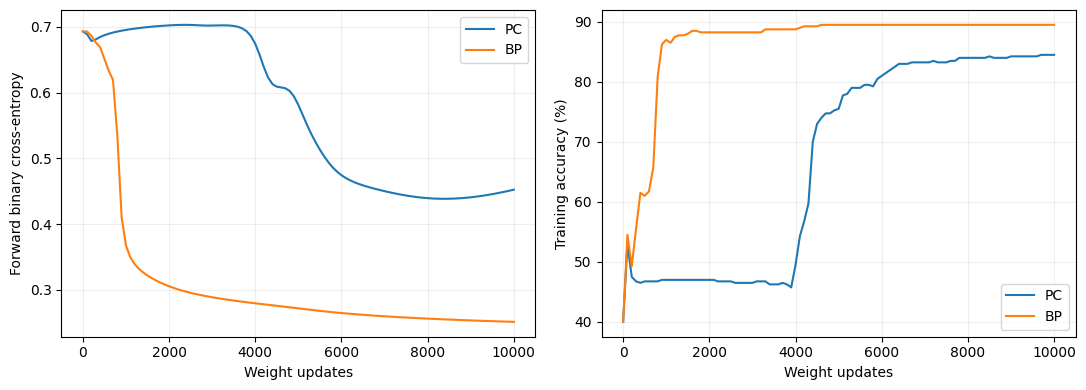

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, history in (("PC", pc_history), ("BP", bp_history)):
    axes[0].plot(history["iteration"], history["cost"], label=label)
    axes[1].plot(history["iteration"], 100 * history["accuracy"], label=label)
axes[0].set_ylabel("Forward binary cross-entropy")
axes[1].set_ylabel("Training accuracy (%)")
for ax in axes:
    ax.set_xlabel("Weight updates")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 18 — Plot both decision boundaries

Reuse your utility. Its plotting callback receives a row-per-example grid, so we transpose it to our column-per-example convention. Pass `Y.ravel()` to Matplotlib for point colors.

Neither model uses labels during `predict`.

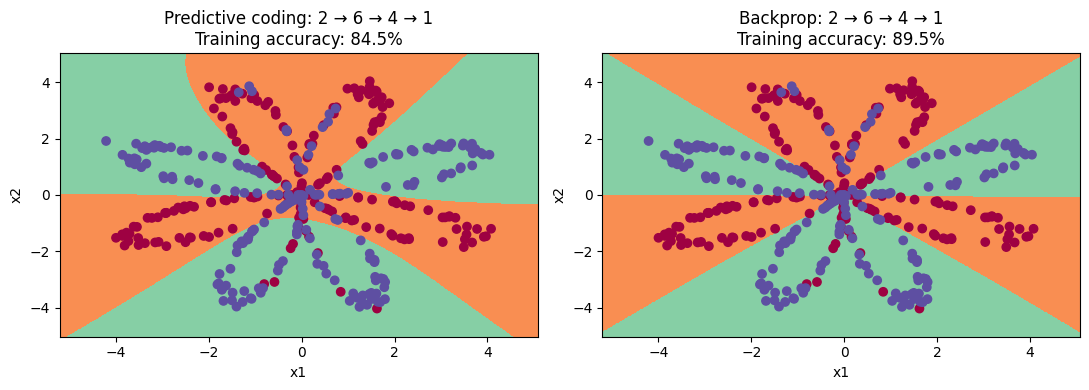

In [19]:
plt.figure(figsize=(11, 4))
for position, (label, parameters) in enumerate(
        (("Predictive coding", pc_parameters), ("Backprop", bp_parameters)), start=1):
    plt.subplot(1, 2, position)
    plot_decision_boundary(lambda points: predict(parameters, points.T), X, Y.ravel())
    accuracy = np.mean(predict(parameters, X) == Y)
    plt.title(f"{label}: 2 → 6 → 4 → 1\nTraining accuracy: {accuracy:.1%}")
plt.tight_layout()
plt.show()

## 19 — Inspect how errors move during inference

Freeze the trained PC weights and repeat inference on the first point. Its label is 0. Track **activities**, **predictions**, and **errors** separately.

At step 0 the hidden residuals are zero, even though the output may be wrong. The output term first nudges `H2`; hidden mismatches then communicate that information to lower layers. Energy descent concerns the joint objective, so do not expect every individual residual or output probability to change monotonically.

Point label: 0
Step     Energy       p(class 1)     ||e1||       ||e2||
   0     0.013971     0.013874     0.000000     0.000000
   1     0.012269     0.012099     0.000000     0.013873
   2     0.010995     0.010884     0.005075     0.008815
   5     0.008580     0.008340     0.010397     0.017376
  10     0.006589     0.006183     0.018466     0.020820
  20     0.004910     0.004286     0.028108     0.020972


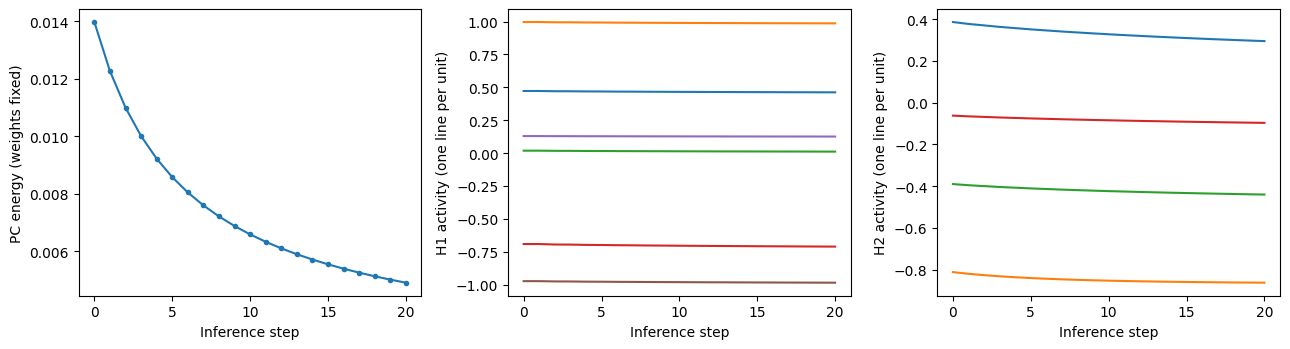

In [20]:
one_X, one_Y = X[:, :1], Y[:, :1]
_, one_cache = forward_propagation(pc_parameters, one_X)
one_state = initialize_activities(one_cache)
trace = {name: [] for name in ("energy", "p", "e1_norm", "e2_norm", "H1", "H2")}

for step in range(INFERENCE_STEPS + 1):
    one_errors = compute_prediction_errors(pc_parameters, one_X, one_Y, one_state)
    trace["energy"].append(compute_energy(one_Y, one_errors))
    trace["p"].append(float(one_errors["p"][0, 0]))
    trace["e1_norm"].append(float(np.linalg.norm(one_errors["e1"])))
    trace["e2_norm"].append(float(np.linalg.norm(one_errors["e2"])))
    trace["H1"].append(one_state["H1"][:, 0].copy())
    trace["H2"].append(one_state["H2"][:, 0].copy())
    if step < INFERENCE_STEPS:
        grads = activity_gradients(pc_parameters, one_errors)
        one_state = {name: value - ACTIVITY_RATE * grads[name]
                     for name, value in one_state.items()}

print("Point label:", int(one_Y[0, 0]))
print("Step     Energy       p(class 1)     ||e1||       ||e2||")
for step in (0, 1, 2, 5, 10, 20):
    if step <= INFERENCE_STEPS:
        print(f"{step:4d}   {trace['energy'][step]:10.6f}   {trace['p'][step]:10.6f}   "
              f"{trace['e1_norm'][step]:10.6f}   {trace['e2_norm'][step]:10.6f}")
assert np.isfinite(trace["energy"]).all()
assert trace["energy"][-1] < trace["energy"][0]
assert np.all(np.diff(trace["energy"]) <= 1e-10), "Reduce activity_rate for stable inference"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(trace["energy"], marker=".")
axes[0].set_ylabel("PC energy (weights fixed)")
axes[1].plot(trace["H1"])
axes[1].set_ylabel("H1 activity (one line per unit)")
axes[2].plot(trace["H2"])
axes[2].set_ylabel("H2 activity (one line per unit)")
for ax in axes:
    ax.set_xlabel("Inference step")
fig.tight_layout()
plt.show()

## What to compare with your backprop functions

| Your backprop step | This PC notebook | What changes? |
|---|---|---|
| `layers` | `layers` | Same architecture |
| `intialize` | `initialize_parameters` | Same draws and shapes; explicit local seed |
| `forwared_propagation` | `forward_propagation` | Same equations; also initializes activities |
| `compute_cost` | `compute_cost`, `compute_energy` | Forward BCE for evaluation; joint energy for PC inference |
| `backwared_propagation` | `infer_activities`, `local_parameter_gradients` | Iterative activity relaxation, followed by local parameter derivatives |
| `update_parameters` | `update_parameters` | Same gradient-descent subtraction |
| `nn_model` | `pc_model` | Adds an inner inference loop before each weight update |
| `predict` | `predict` | Same label-free forward prediction |

### Why this is discriminative PC

Predictions flow from inputs toward the class label. Training fixes the observed input and target, infers hidden activities, then changes the weights. We are not learning to reconstruct the input from a class label.

### Why PC and BP need not have identical gradients

Ordinary PC changes hidden activities and recomputes predictions during inference. BP differentiates the feedforward computation at its original activations. Exact or limiting correspondences require additional conditions; merely running inference longer does not make this implementation identical to BP.

For context, see [A Theoretical Framework for Inference and Learning in Predictive Coding Networks](https://arxiv.org/abs/2207.12316) and [Predictive Coding Approximates Backprop Along Arbitrary Computation Graphs](https://arxiv.org/abs/2006.04182). The finite-difference checks above verify the particular mixed Gaussian/Bernoulli energy used here.

### Small experiments after reading the walkthrough

- Set `inference_steps` to 1: at forward initialization, the first step only changes `H2`, delaying teaching signals to the lowest layer.
- Try 5, 20, and 50 inference steps from the same initial weights, comparing both accuracy and elapsed time.
- Reduce `activity_rate` and inspect the energy trace to see slower relaxation.
- Change `weight_rate` independently to separate inference stability from parameter-learning behavior.

With zero inference steps, both hidden residuals remain zero: the hidden weights receive zero local gradients for that update. This is a useful diagnostic, not a substitute for training the full PC model.